# Phase 4 — Feature Engineering: FD004
**Notebook:** `12b_Feature_Engineering_FD004.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

Same two decisions and the same rules as FD002 (`06b_Feature_Engineering_FD002`), applied automatically:

| Decision | Candidates | Rule (fixed in advance) |
|---|---|---|
| Rolling window (tabular models) | 0, 10, 20, 30, 50, 80, 100, 150, 200, 300, 400 | Smallest window within **0.5** RF RMSE of the best, then check `cycle` |
| LSTM input | short window of sensors / longest allowed window of sensors / longest window of sensors **+ rolling means** | Lowest mean RMSE over 2 seeds |

The longest allowed LSTM window is the shortest test engine, capped at 30 (FD001's choice). The "+ rolling means" variant is the design you approved for FD002/FD004. If it wins here too, the notebook uses it. To force the plain-sensor design, set `LSTM_VARIANT` at the top of Cell 6.

`src/feature_engineering.py` is reused unchanged. Only the frozen Phase 3 pipeline from `12_Preprocessing_FD004` is loaded.

⚙️ Use a **T4 GPU** runtime if possible (for the LSTM probe). About 6–12 minutes.

## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FD, SEED = "FD004", 42
PROC_DIR, PREP_DIR = PROJECT_DIR / "data" / "processed" / FD, PROJECT_DIR / "models" / FD / "preprocessing"
FIG_DIR, FE_REPORT = PROJECT_DIR / "reports" / "figures" / FD, PROJECT_DIR / "reports" / "feature_engineering" / FD
FE_REPORT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
print("Device:", DEVICE)

Device: cpu


## Cell 2 — Load the frozen Phase 3 artifacts

In [2]:
# Cell 2 — Load
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.regime_preprocessing as rp, src.model_training as mt
for m in (dl, pp, ev, fe, rp, mt):
    importlib.reload(m)
split = json.loads((PROC_DIR / "split.json").read_text())
train_ids, val_ids = split["train_engine_ids"], split["val_engine_ids"]
meta = json.loads((PREP_DIR / "pipeline_metadata.json").read_text())
prep = rp.load_preprocessor(PREP_DIR)
cuts = pd.read_csv(PROC_DIR / "val_cut_points.csv")
CAP, B = meta["rul_cap"], prep.feature_cols
MAX_SEQ = min(meta["max_lstm_seq_len"], 30)
d = dl.load_dataset(FD, RAW_DIR)
full = pp.add_train_rul(d["train"], cap=CAP)
tr_s = prep.transform(full[full.engine_id.isin(train_ids)]).reset_index(drop=True)
va_s = prep.transform(full[full.engine_id.isin(val_ids)]).reset_index(drop=True)
print(f"{type(prep).__name__} | cap {CAP} | {len(B)} sensors | longest LSTM window {MAX_SEQ}")
print(f"train rows {len(tr_s)} | val rows {len(va_s)} | validation points {len(cuts)}")

RegimePreprocessor | cap 100 | 14 sensors | longest LSTM window 19
train rows 49147 | val rows 12102 | validation points 500


## Cell 3 — Causality checks (no future data, per-engine windows, correct slope)

In [3]:
# Cell 3 — Checks
f1 = fe.add_rolling_features(va_s, B, 200)
eid = val_ids[0]
bad = va_s.copy(); bad.loc[(bad.engine_id == eid) & (bad.cycle > 60), B] += 50
f2 = fe.add_rolling_features(bad, B, 200)
past = (f1.engine_id == eid) & (f1.cycle <= 60); cols = [c for c in f1.columns if c != "RUL"]
assert np.allclose(f1.loc[past, cols].values, f2.loc[past, cols].values); print("✅ Causal")
first = f1.groupby("engine_id").head(1)
assert np.allclose(first[f"{B[0]}_mean_200"], first[B[0]]) and (first[f"{B[0]}_std_200"] == 0).all(); print("✅ Per-engine windows")
g = f1[f1.engine_id == eid].sort_values("cycle")
assert np.isclose(np.polyfit(g.cycle.values[:50], g[B[0]].values[:50], 1)[0], g[f"{B[0]}_slope_200"].values[49]); print("✅ Slope = np.polyfit")

✅ Causal
✅ Per-engine windows
✅ Slope = np.polyfit


## Cell 4 — Rolling window experiment

window   0, cycle=True: LR 22.70 | RF 19.64


window  10, cycle=True: LR 21.05 | RF 19.39


window  20, cycle=True: LR 20.87 | RF 17.79


window  30, cycle=True: LR 20.46 | RF 15.39


window  50, cycle=True: LR 19.56 | RF 13.58


window  80, cycle=True: LR 18.36 | RF 13.06


... (2 outputs left out)

window 200, cycle=True: LR 17.45 | RF 12.12


window 300, cycle=True: LR 17.61 | RF 11.93


window 400, cycle=True: LR 17.62 | RF 11.88

Best RF window 400 (11.88) → chosen by the 0.5 rule: 200 (12.12)


window 200, cycle=False: LR 17.47 | RF 13.23
cycle at window 200: with 12.12 vs without 13.23 → include_cycle = True


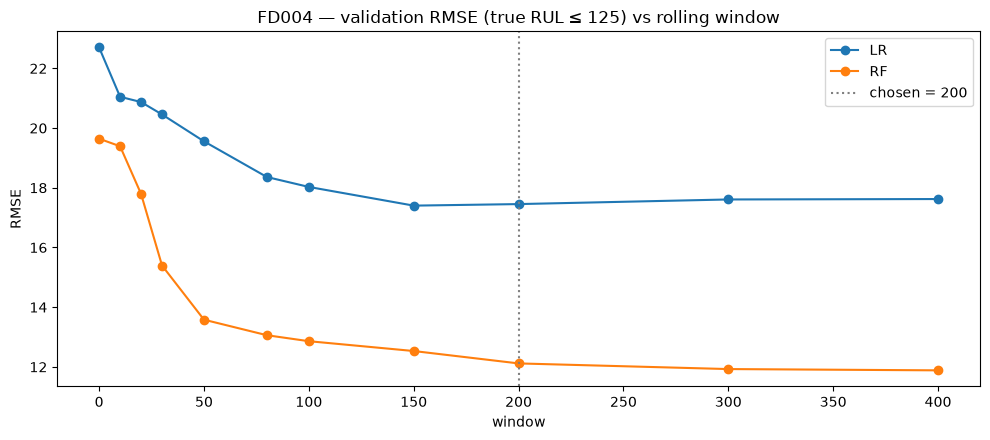

In [4]:
# Cell 4 — Window experiment (LR + small RF, cycle included)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
y = cuts.true_rul.values; LE = y <= 125

def probe_window(w, inc):
    trf, names = fe.build_tabular(tr_s, B, w, inc); vaf, _ = fe.build_tabular(va_s, B, w, inc)
    X = fe.rows_at(vaf, cuts)[names]; out = []
    for name, model in [("LR", LinearRegression()),
                        ("RF", RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features=0.33,
                                                     max_samples=0.5, n_jobs=-1, random_state=SEED))]:
        model.fit(trf[names], trf["RUL"]); pred = np.clip(model.predict(X), 0, None)
        out.append({"window": w, "cycle_feat": inc, "probe": name, "n_features": len(names),
                    "RMSE_le125": ev.rmse(y[LE], pred[LE]), "bias_le125": float(np.mean(pred[LE] - y[LE])),
                    "NASA_per_point_le125": ev.nasa_score(y[LE], pred[LE]) / LE.sum(), "RMSE_all": ev.rmse(y, pred)})
    print(f"window {w:3d}, cycle={inc}: LR {out[0]['RMSE_le125']:.2f} | RF {out[1]['RMSE_le125']:.2f}")
    return out

rows = []
for w in [0, 10, 20, 30, 50, 80, 100, 150, 200, 300, 400]:
    rows += probe_window(w, True)
win = pd.DataFrame(rows)
rf = win[win.probe == "RF"].set_index("window")["RMSE_le125"]
WINDOW = int(min(w for w in rf.index if rf[w] <= rf.min() + 0.5))
print(f"\nBest RF window {int(rf.idxmin())} ({rf.min():.2f}) → chosen by the 0.5 rule: {WINDOW} ({rf[WINDOW]:.2f})")
rows += probe_window(WINDOW, False)
win = pd.DataFrame(rows); win.to_csv(FE_REPORT / "window_experiment.csv", index=False)
on = rf[WINDOW]; off = win[(win.window == WINDOW) & ~win.cycle_feat & (win.probe == "RF")].RMSE_le125.iloc[0]
INCLUDE_CYCLE = bool(on <= off)
print(f"cycle at window {WINDOW}: with {on:.2f} vs without {off:.2f} → include_cycle = {INCLUDE_CYCLE}")
fig, ax = plt.subplots(figsize=(10, 4.5))
for probe, sub in win[win.cycle_feat].groupby("probe"):
    ax.plot(sub.window, sub.RMSE_le125, marker="o", label=probe)
ax.axvline(WINDOW, color="grey", ls=":", label=f"chosen = {WINDOW}")
ax.set(title=f"{FD} — validation RMSE (true RUL ≤ 125) vs rolling window", xlabel="window", ylabel="RMSE"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "12_window_experiment.png", dpi=150, bbox_inches="tight"); plt.show()

## Cell 5 — LSTM input experiment (small LSTM, fixed 12 epochs, 2 seeds)

In [5]:
# Cell 5 — LSTM probe
tr_r, va_r = fe.add_rolling_features(tr_s, B, WINDOW), fe.add_rolling_features(va_s, B, WINDOW)
MEANS = [f"{c}_mean_{WINDOW}" for c in B]
VARIANTS = {f"L15": (15, B), f"L{MAX_SEQ}": (MAX_SEQ, B), f"L{MAX_SEQ} + means": (MAX_SEQ, B + MEANS)}
rows = []
for name, (L, cols) in VARIANTS.items():
    X_tr, y_tr, _ = fe.make_sequences(tr_r, cols, L); X_cut = fe.sequences_at(va_r, cols, L, cuts)
    for seed in (42, 7):
        model, hist, _ = mt.train_lstm({"hidden": 64, "layers": 1}, X_tr, y_tr, CAP, epochs=12,
                                       device=DEVICE, seed=seed, verbose=False)
        pred = mt.lstm_predict(model, X_cut, CAP, DEVICE)
        rows.append({"variant": name, "seq_len": L, "n_inputs": len(cols), "seed": seed,
                     "RMSE_le125": ev.rmse(y[LE], pred[LE]), "bias_le125": float(np.mean(pred[LE] - y[LE]))})
        print(f"{name:14s} seed {seed}: RMSE≤125 {rows[-1]['RMSE_le125']:.2f}")
lstm_exp = pd.DataFrame(rows); lstm_exp.to_csv(FE_REPORT / "lstm_input_experiment.csv", index=False)
summary = lstm_exp.groupby("variant", sort=False).agg(seq_len=("seq_len", "first"), n_inputs=("n_inputs", "first"),
                                                       RMSE_mean=("RMSE_le125", "mean"), RMSE_min=("RMSE_le125", "min"),
                                                       RMSE_max=("RMSE_le125", "max"))
display(summary.round(2))
LSTM_VARIANT = summary.RMSE_mean.idxmin(); print("Chosen:", LSTM_VARIANT)

L15            seed 42: RMSE≤125 17.62


L15            seed 7: RMSE≤125 18.30


L19            seed 42: RMSE≤125 17.73


L19            seed 7: RMSE≤125 17.22


L19 + means    seed 42: RMSE≤125 15.74


L19 + means    seed 7: RMSE≤125 14.84


,seq_len,n_inputs,RMSE_mean,RMSE_min,RMSE_max
variant,,,,,
L15,15,14,17.96,17.62,18.30
L19,19,14,17.48,17.22,17.73
L19 + means,19,28,15.29,14.84,15.74


Chosen: L19 + means


## Cell 6 — Final LSTM sequences + feature_config.json

In [6]:
# Cell 6 — Freeze (to force plain sensors: LSTM_VARIANT = f"L{MAX_SEQ}")
SEQ_LEN, LSTM_FEATURES = VARIANTS[LSTM_VARIANT]
X_tr, y_tr, m_tr = fe.make_sequences(tr_r, LSTM_FEATURES, SEQ_LEN)
X_cut = fe.sequences_at(va_r, LSTM_FEATURES, SEQ_LEN, cuts)
assert int((d["test"].groupby("engine_id").cycle.max() < SEQ_LEN).sum()) == 0
print(f"{LSTM_VARIANT}: train windows {X_tr.shape} | cut points {X_cut.shape} | all test engines long enough ✅")
tabular_names = fe.tabular_feature_names(B, WINDOW, INCLUDE_CYCLE)
feature_config = {
    "dataset": FD, "base_features": B, "preprocessing": f"{type(prep).__name__} (models/{FD}/preprocessing)",
    "tabular": {"window": WINDOW, "include_cycle": INCLUDE_CYCLE, "rolling_stats": ["mean", "std", "slope"],
                "min_periods": 1, "feature_order": tabular_names, "n_features": len(tabular_names)},
    "lstm": {"variant": LSTM_VARIANT, "seq_len": SEQ_LEN, "features": LSTM_FEATURES, "n_features": len(LSTM_FEATURES),
             "rolling_window": WINDOW if any("_mean_" in c for c in LSTM_FEATURES) else None,
             "label": "capped RUL at last cycle of window", "min_history_required": SEQ_LEN,
             "padding": "none (shorter histories rejected)"},
    "cycle_requirement": "cycle must count from the start of the engine's recorded operation (cycle 1)",
    "selection_evidence": [f"reports/feature_engineering/{FD}/window_experiment.csv",
                           f"reports/feature_engineering/{FD}/lstm_input_experiment.csv"],
}
(PROJECT_DIR / "models" / FD / "feature_config.json").write_text(json.dumps(feature_config, indent=2))
print(f"✅ Saved feature_config.json — tabular: {len(tabular_names)} features (window {WINDOW}, cycle={INCLUDE_CYCLE}), "
      f"LSTM: {SEQ_LEN}×{len(LSTM_FEATURES)} ({LSTM_VARIANT})")

L19 + means: train windows (45565, 19, 28) | cut points (500, 19, 28) | all test engines long enough ✅
✅ Saved feature_config.json — tabular: 57 features (window 200, cycle=True), LSTM: 19×28 (L19 + means)


## Reference results (full local run)
**Window experiment (RMSE ≤ 125, cycle included):**

| Window | 0 | 10 | 20 | 30 | 50 | 80 | 100 | 150 | 200 | 300 | 400 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| LR | 22.70 | 21.05 | 20.87 | 20.46 | 19.56 | 18.36 | 18.03 | 17.40 | 17.45 | 17.61 | 17.62 |
| RF | 19.64 | 19.39 | 17.79 | 15.39 | 13.58 | 13.06 | 12.86 | 12.53 | 12.12 | 11.93 | 11.88 |

→ **window 200**, cycle included = True.

**LSTM input probe (mean over 2 seeds, min–max):**

| Variant | RMSE ≤ 125 |
|---|---:|
| L15 | 17.96 (17.62–18.30) |
| L19 | 17.48 (17.22–17.73) |
| L19 + means | 15.29 (14.84–15.74) |

→ **L19 + means** (19 × 28 inputs).

## ✅ Verify
Cell 3: three ✅ · Cell 4: chosen window printed · Cell 5: LSTM summary · Cell 6: `✅ Saved feature_config.json`.

**Next:** `13_Model_Training_FD004`.